# 6. 节点执行和容错机制


节点执行失败时，如果未做任何处理，可能导致整个运行图执行失败。为了提升运行图的稳定性，处理临时故障、超时、异常恢复以及重复计算等问题，LangGraph 提供了一系列节点执行与容错机制：重试、超时设置、异常处理和节点缓存。对应关系如下。

| 问题/场景 | 对应机制 | 机制类型 | 说明 |
| --- | --- | --- | --- |
| 临时故障 | 重试 Retry | 节点容错机制 | 网络抖动、接口偶发失败、模型服务短暂不可用，可以通过重试机制再次执行节点。 |
| 超时 | 超时设置 Timeout | 节点容错机制 | 某个节点执行时间过长，可以通过超时限制避免图运行被长时间阻塞。 |
| 异常恢复 | 异常处理 Error Handling | 节点容错机制 | 节点抛出异常后，通过异常捕获、兜底逻辑、降级返回、路由到错误处理节点等方式恢复流程。 |
| 重复计算 | 缓存 Cache | 节点执行优化机制 | 相同输入反复触发耗时节点，可以通过节点缓存避免重复执行，提高性能。 |


## 6.1 LangGraph的节点容错机制
LangGraph 提供了三种异常处理机制

- `retries`：重试机制。节点执行失败时，根据重试策略自动重新执行。
- `Timeouts`：超时控制。限制单次节点执行的最大等待时间。
- `Error Handling`：错误处理。重试次数耗尽后，执行特定的异常处理逻辑。

三者的执行顺序如下：
1. 节点开始执行。
2. 如果节点执行超时或抛出异常，本次节点尝试失败。
3. 重试策略 RetryPolicy 判断该异常是否需要重试。
4. 如果满足重试条件，并且尚未达到最大尝试次数，则重新执行节点。
5. 如果重试次数耗尽，节点仍然失败，则进入 error_handler 错误处理逻辑。
6. 如果没有配置错误处理逻辑，则异常继续向外抛出，可能导致整个图运行失败。

需要注意：
- 重试机制 是当前版本中最常用、最基础的节点容错能力。
- 超时控制 和 错误处理 是较新版本引入的能力，要求 langgraph>=1.2。

## 6.2 重试机制
### 6.2.1 基本用法
重试机制用于处理临时性异常，例如网络抖动、远程服务短暂不可用、API 偶发失败等。

在添加节点时，可以通过 `retry_policy` 配置节点的重试策略。

D:\ProgramData\miniconda3\envs\langgraph\Lib\site-packages\langgraph\cache\base\__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer
2026-10-15 15:48:51.622 | INFO     | __main__:node_a:12 - node a 运行
2026-10-15 15:48:52.178 | INFO     | __main__:node_a:12 - node a 运行
2026-10-15 15:48:53.180 | INFO     | __main__:node_a:12 - node a 运行
2026-10-15 15:48:53.181 | INFO     | __main__:<module>:32 - 重试次数耗尽: 网络连接超时...


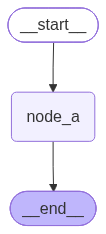

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import RetryPolicy

from requests.exceptions import HTTPError
from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState) -> EmptyState:
    logger.info(f"node a 运行")
    raise HTTPError("网络连接超时...")

builder = StateGraph(state_schema=EmptyState)
builder.add_node(
    "node_a",
    node_a,
    retry_policy=RetryPolicy(
        max_attempts=3,
        jitter=False
    )
)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()

try:
    graph.invoke({})
except HTTPError as e:
    logger.info("重试次数耗尽: {}", e)

from IPython.display import display
display(graph)

本例中：
- `max_attempts=3` 表示最多尝试 3 次。
- 这 3 次包括首次执行，而不是首次失败后的 3 次重试。
- 因此，节点总共会被调用 3 次。
- 3 次全部失败后，异常继续向外抛出。
- 外层的 try...except 捕获该异常，并打印日志。

### 6.2.2 重试策略配置详解
超时策略通过 `RetryPolicy` 配置，其主要参数如下

| 参数                                            | 类型                   | 默认值              | 描述 |
|-----------------------------------------------|----------------------|------------------| --- |
| `max_attempts` | int | 3 | 最大尝试次数（包括首次执行） |
| `initial_interval` | float | 0.5 | 第一次重试前的等待时间，单位：秒 |
| `backoff_factor` | float | 2.0 | 每次重试后等待时间的放大倍数 |
| `max_interval` | float | 128.0 | 相邻两次重试之间的最大等待时间，单位：秒 |
| `jitter` | bool | True | 是否为重试间隔添加随机抖动 |
| `retry_on` | type[Exception] | Sequence[type[Exception]] | Callable[[Exception], bool]	default_retry_on	哪些异常需要触发重试 |


#### 6.2.2.1. `max_attempts`
`max_attempts` 表示最大尝试次数，包括首次执行。

例如：

```
RetryPolicy(max_attempts=3)
```
表示：
```
第 1 次：首次执行
第 2 次：第 1 次重试
第 3 次：第 2 次重试
如果第 3 次仍然失败，则不再继续重试。
```


#### 6.2.2.2 `initial_interval`
`initial_interval` 表示第一次重试前的等待时间，单位为秒。

例如：

```python
RetryPolicy(initial_interval=0.5)
```
表示首次失败后，等待 0.5s 再进行第一次重试。


#### 6.2.2.3 `backoff_factor`
`backoff_factor` 表示重试间隔的增长倍数。

默认情况下，`RetryPolicy` 使用指数退避策略：

```
第一次失败后：等待 initial_interval
第二次失败后：等待 initial_interval * backoff_factor
第三次失败后：继续乘以 backoff_factor
```
例如：

```
RetryPolicy(
    initial_interval=0.5,
    backoff_factor=2.0
)
```
等待时间大致为：
```
0.5s -> 1.0s -> 2.0s -> 4.0s ...
```

#### 6.2.2.4 `max_interval`
`max_interval` 表示相邻两次重试之间的最大等待时间。

即使指数退避计算出的等待时间继续增长，也不会超过 max_interval。

例如：
```
RetryPolicy(
    initial_interval=1,
    backoff_factor=2,
    max_interval=5
)
```
等待时间大致为：
```
1s -> 2s -> 4s -> 5s -> 5s ...
```

#### 6.2.2.5. `jitter`
`jitter` 表示是否为重试间隔添加随机抖动（添加随机数，可正可负）。

在并发场景中，如果大量任务同时失败，并且按照固定间隔同时重试，可能导致服务在某个时间点被大量请求打爆。

加入 `jitter` 后，不同任务的重试时间会被打散，从而降低瞬时流量峰值。

上述案例中，为了让日志时间更稳定，观察指数退避策略，所以设置了：

```
RetryPolicy(jitter=False)
```
如果是生产环境，通常建议保留默认值：
```
RetryPolicy(jitter=True)
```

#### 6.2.2.6. `retry_on`
`retry_on` 用于设置哪些异常需要触发重试。

它支持三种写法：

写法一：指定单个异常类型
```
RetryPolicy(retry_on=HTTPError)
```
表示只有抛出 HTTPError 时才重试。

写法二：指定多个异常类型
```
RetryPolicy(
    retry_on=(HTTPError, ConnectionError)
)
```
表示抛出 HTTPError 或 ConnectionError 时触发重试。

写法三：自定义判断函数
```
def should_retry(exc: Exception) -> bool:
    return isinstance(exc, HTTPError)

RetryPolicy(retry_on=should_retry)
```

这种写法最灵活。

`should_retry` 接收一个异常实例，返回一个布尔值：
- 返回 True：表示该异常需要重试。
- 返回 False：表示该异常不需要重试。


## 6.3 超时控制

### 6.3.1 使用要求
超时控制用于限制单次节点执行的最大耗时，避免某个节点因为外部服务无响应、网络阻塞或异步任务卡住而长时间不返回。

需要注意：

1. 版本要求

    节点级超时控制要求：`langgraph>=1.2`

2. 节点类型要求

    节点级超时控制仅适用于异步节点，即使用 `async def` 定义的节点。

    同步节点一旦开始执行，通常会阻塞当前线程。Python 进程内缺少一种通用、安全的机制，可以从外部强行终止正在运行的同步函数；如果强行中断，可能导致资源未释放、锁未释放或副作用处于不一致状态。因此，LangGraph  的节点级超时更适合用于异步节点。对于同步节点，应优先在节点内部使用具体库提供的超时参数，例如 HTTP  客户端、数据库驱动或 SDK 自带的 timeout 配置。

### 6.3.2 核心思想

超时控制的核心思想是：

> 为单次节点设置超时时间，运行时长超过超时时间，节点运行失败，并抛出超时异常。

在 `add_node` 中通过 `timeout=` 配置超时策略。

例如：
```
from langgraph.types import TimeoutPolicy

builder.add_node(
    "call_model",
    call_model,
    timeout=TimeoutPolicy(run_timeout=60)
)
```
这里的含义是：

- `call_model` 节点单次执行最多运行 60 秒。
- 如果超过 60 秒仍未完成，则触发超时。
- 超时后会抛出 `NodeTimeoutError`。
- 该异常会交给 `RetryPolicy` 判断是否需要重试。
- 如果重试次数耗尽，才会进入错误处理逻辑。

### 6.3.3 TimeoutPolicy 简要说明
`TimeoutPolicy` 常见参数包括：

| 参数	| 描述 |
| --- | --- |
| `run_timeout`| 超时时间，即单次节点运行的最长时间 |
| `idle_timeout`| 节点没有可观察进展（如写状态、流式输出等）时的最长空闲时间 |
| `refresh_on`| 空闲时间的刷新方式，可以是手动刷新或自动刷新。默认为自动刷新，此时写状态、流式输出等都会刷新 |


## 6.4 错误处理
### 6.4.1 使用要求

错误处理机制要求：`langgraph>=1.2`

### 6.4.2 核心思想
错误处理机制用于在节点最终失败后，执行兜底逻辑。

节点执行失败时，整体顺序如下：
```
节点执行失败
    ↓
是否满足 retry_policy
    ↓
满足则继续重试，直到重试次数耗尽，否则直接进行下一步
    ↓
进入 error_handler
    ↓
执行兜底恢复逻辑
```
在 `add_node` 中通过 `error_handler=` 设置错误处理逻辑。

例如：
```
builder.add_node(
    "call_api",
    call_api,
    retry_policy=RetryPolicy(max_attempts=3),
    error_handler=handle_api_error
)
```
其含义是：
- `call_api` 执行失败。
- `RetryPolicy` 判断是否重试。
- 最多尝试 3 次。
- 3 次仍然失败后，调用 `handle_api_error`。
- `handle_api_error` 可以返回状态更新，也可以通过 Command 路由到其他节点。

错误处理适合以下场景：
- API 调用失败后返回兜底结果。
- 远程服务失败后切换到备用服务。
- 多步骤业务流程中执行补偿逻辑。
- 不希望整个图因为单个节点失败而直接终止。

## 6.5 节点缓存
### 6.5.1 什么是节点缓存？

节点缓存是指：

> 将节点的历史运行结果保存下来，后续当节点收到相同输入时，不再重复执行节点函数，而是直接返回之前缓存的结果。

节点缓存主要用于减少重复计算，降低延迟和成本。

例如，某个节点内部需要：
- 调用大模型
- 调用外部 API
- 查询远程数据库
- 执行复杂计算
- 进行耗时的数据处理

如果相同输入会多次出现，那么可以考虑启用节点缓存。

### 6.5.2 适用场景
节点缓存通常适用于同时满足以下条件的场景：

1. 节点函数具有确定性

    相同输入应当产生相同输出。

    例如：
   ```
   输入 A -> 输出 B
   再次输入 A -> 仍然输出 B
   ```

2. 节点执行成本较高

    例如大模型调用、API 请求、复杂计算、耗时查询等。

3. 相同输入会重复出现

    例如多次调试图、重复执行相同流程、多个分支复用同一中间结果等。

4. 输入能够被缓存键函数稳定处理

    缓存是以 键值对 形式存储的，每个缓存都有唯一的 Key，缓存键函数 用于生成唯一键。

    默认情况下，CachePolicy 使用 default_cache_key 作为缓存键函数。后者基于节点输入调用 pickle 库的序列化功能生成缓存唯一键。

    使用默认缓存键函数时，建议输入尽量使用简单、稳定、可序列化的数据结构，例如：

    - `str`
    - `int`
    - `float`
    - `bool`
    - `dict`
    - `list`
    - `tuple`

    如果节点输入中包含复杂对象、文件句柄、数据库连接、模型实例、动态对象等，建议自定义 `key_func`，避免缓存 `Key` 不稳定或无法生成。

### 6.5.3. 基本用法
节点缓存需要两步配置。

第一步：为节点配置 `cache_policy`

在 `add_node` 调用时，通过 `cache_policy=` 设置节点缓存策略。

```python
builder.add_node(
    "node_a",
    node_a,
    cache_policy=CachePolicy(ttl=10)
)
```

第二步：编译图时启用缓存后端

仅仅为节点配置 `cache_policy` 还不够，还需要在编译图时指定缓存后端。

例如：
```python
graph = builder.compile(cache=InMemoryCache())
```
其中：
- `CachePolicy`：声明节点是否启用缓存，以及缓存策略是什么。
- `InMemoryCache`：声明缓存数据实际保存在哪里。

如果只配置 `cache_policy`，但编译图时没有传入 `cache=`，缓存不会真正生效。

2026-10-15 16:05:12.289 | INFO     | __main__:<module>:33 - 首次调用图
2026-10-15 16:05:12.290 | INFO     | __main__:node_a:15 - node_a 被调用, user: 小明
2026-10-15 16:05:15.291 | INFO     | __main__:node_a:17 - node_a 耗时操作执行完毕
2026-10-15 16:05:15.295 | INFO     | __main__:<module>:34 - 运行结果: {'user': '小明', 'invoke_counts': 1}


2026-10-15 16:05:15.296 | INFO     | __main__:<module>:35 - 相同输入再次调用图
2026-10-15 16:05:15.297 | INFO     | __main__:<module>:36 - 运行结果: {'user': '小明', 'invoke_counts': 1}


2026-10-15 16:05:15.298 | INFO     | __main__:<module>:37 - 不同输入再次调用图
2026-10-15 16:05:15.299 | INFO     | __main__:node_a:15 - node_a 被调用, user: 小花
2026-10-15 16:05:18.300 | INFO     | __main__:node_a:17 - node_a 耗时操作执行完毕
2026-10-15 16:05:18.301 | INFO     | __main__:<module>:38 - 运行结果: {'user': '小花', 'invoke_counts': 1}


2026-10-15 16:05:18.301 | INFO     | __main__:<module>:39 - 不同输入再次调用图
2026-10-15 16:05:18.302 | INFO     | __main__:node_a:15 - node_a 被调用, user: 小花
2026-10-15 16:05:21.303 | INFO

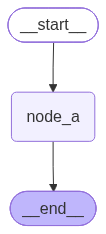

In [2]:
import time
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.cache.memory import InMemoryCache
from langgraph.types import CachePolicy

from operator import add
from loguru import logger

class EmptyState(TypedDict):
    user: str
    invoke_counts: Annotated[int, add]

def node_a(state: EmptyState) -> EmptyState:
    logger.info("node_a 被调用, user: {}", state["user"])
    time.sleep(3) # 模拟耗时操作
    logger.info("node_a 耗时操作执行完毕")

    return {
        "invoke_counts": 1
    }

builder = StateGraph(state_schema=EmptyState)
builder.add_node(
    "node_a",
    node_a,
    cache_policy=CachePolicy(ttl=10)
)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile(cache=InMemoryCache())
logger.info("首次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小明", "invoke_counts": 0}))
logger.info("相同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小明", "invoke_counts": 0}))
logger.info("不同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小花", "invoke_counts": 0}))
logger.info("不同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小花", "invoke_counts": 2}))
time.sleep(10) # 确保第一次调用缓存失效
logger.info("10秒后相同输入再次调用图，此时缓存已失效")
logger.info("运行结果: {}", graph.invoke({"user": "小明", "invoke_counts": 0}))

from IPython.display import display
display(graph)

### 6.5.4. 缓存策略配置详解
缓存策略通过 `CachePolicy` 配置，只有两个配置项

| 参数 | 描述 |
| --- | --- |
| `key_func` |	根据节点输入生成缓存 Key 的函数 |
| `ttl` |	缓存键值对的存活时间，单位为秒 |

#### 6.5.4.1 `key_func`
`key_func` 用于根据节点输入生成唯一的缓存 Key。

节点缓存本质上是一个 K-V 缓存：
```
缓存 Key -> 节点运行结果
```
当节点再次执行时，LangGraph 会先根据当前输入计算缓存 `Key`：
- 如果缓存 `Key` 已存在，并且没有过期，则直接返回缓存结果。
- 如果缓存 `Key` 不存在，或者已经过期，则正常执行节点函数，并将结果写入缓存。

默认缓存键函数是 `default_cache_key`。

其核心实现如下：
```python
def default_cache_key(*args: Any, **kwargs: Any) -> str | bytes:
    """Default cache key function that uses the arguments and keyword arguments to generate a hashable key."""
    import pickle

    # protocol 5 strikes a good balance between speed and size
    return pickle.dumps((_freeze(args), _freeze(kwargs)), protocol=5, fix_imports=False)
```
它会把节点输入参数经过处理后，使用 pickle 序列化为字节序列，并将后者作为缓存 Key。

#### 6.5.4.2 `ttl`
`ttl` 表示缓存的存活时间，单位为秒。

例如：
```
CachePolicy(ttl=10)
```
表示缓存结果最多保存 10 秒。

如果设置为：
```
CachePolicy(ttl=None)
```
表示缓存不会因为时间原因自动过期。

不过在实际项目中，不建议随意设置永久缓存。

如果节点依赖外部状态，例如：
- 当前时间
- 远程 API 数据
- 数据库查询结果
- 用户权限
- 环境变量
- 模型版本
- 提示词版本

那么应该根据业务场景设置合适的 `ttl`，或者把这些变量纳入缓存 `Key` 的计算逻辑。

## 6.6 全图默认配置
### 6.6.1 使用要求
默认配置功能要求：`langgraph>=1.2`

### 6.6.2 核心思想
当多个节点都需要配置相同的执行策略时，如果每个节点都重复配置，繁琐且耗时。

例如：
```
builder.add_node(
    "node_a",
    node_a,
    retry_policy=RetryPolicy(max_attempts=3)
)

builder.add_node(
    "node_b",
    node_b,
    retry_policy=RetryPolicy(max_attempts=3)
)

builder.add_node(
    "node_c",
    node_c,
    retry_policy=RetryPolicy(max_attempts=3)
)
```
在较新版本中，可以通过 `set_node_defaults` 为所有节点设置默认配置，即全图默认配置 Graph defaults。

默认配置可以包括：
- `retry_policy`
- `timeout`
- `error_handler`
- `cache_policy`

这样可以避免在每个 `add_node` 中重复相同配置。

## 6.7 小结
本章介绍了 LangGraph 中节点执行与容错相关的能力。

总结如下：

| 机制                              | 机制类型                                     | 作用                  | 版本要求             |
|---------------------------------|------------------------------------------|---------------------|------------------|
| 重试机制 Retries                    | 节点容错机制	| 节点失败后自动重试           |                  |
| 超时设置 Timeouts | 节点容错机制	| 限制单次节点执行时间           | 要求 langgraph>=1.2 |
| 错误处理 Error Handling | 节点容错机制	| 重试耗尽后执行兜底逻辑                       | 要求 langgraph>=1.2 |
| 节点缓存 Node Cache | 节点执行优化机制	| 缓存节点历史运行结果                      |                  |
| 全图默认配置 Graph defaults | 默认策略配置	| 为所有节点设置默认执行策略 | 要求 langgraph>=1.2 |

实际使用时，可以按照以下原则选择：
1. 临时性失败：优先使用 RetryPolicy。
2. 外部服务可能卡住：使用 timeout 控制单次节点执行时间。
3. 失败后需要兜底恢复：使用 error_handler。
4. 相同输入重复执行且成本较高：使用 CachePolicy。
5. 多个节点使用相同策略：使用 set_node_defaults 统一配置。

其中，**重试机制** 和 **节点缓存** 是本课程的重点。